In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
url = 'https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv'
df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (178, 14)


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [3]:
# Separating the features (X) and the target variable (y, represents Wine class)
X = df.drop(columns=['Customer_Segment'])
y = df['Customer_Segment']

# Standardizing the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
# Applying PCA to project the data onto the 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Calculate explained variance ratio
explained_variance = pca.explained_variance_ratio_
print(f"Explained Variance by PC1: {explained_variance[0]:.2%}")
print(f"Explained Variance by PC2: {explained_variance[1]:.2%}")
print(f"Total Explained Variance: {sum(explained_variance):.2%}")

Explained Variance by PC1: 36.20%
Explained Variance by PC2: 19.21%
Total Explained Variance: 55.41%


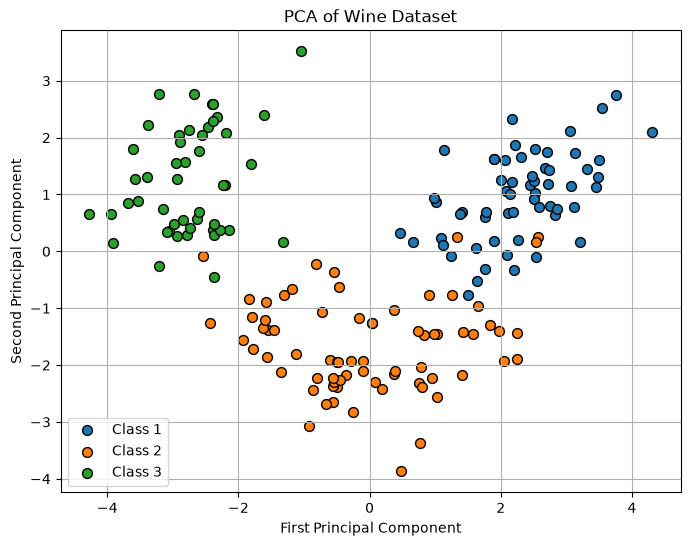

In [5]:
plt.figure(figsize=(8, 6))

# Scatter plot color-coded by the target classes (Customer_Segment)
for label in np.unique(y):
    plt.scatter(X_pca[y == label, 0], X_pca[y == label, 1], label=f'Class {label}', edgecolors='k', s=50)

plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA of Wine Dataset')
plt.legend()
plt.grid(True)
plt.show()